# Summarize and plot felsenstein codes

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import tskit

In [39]:
def clade_phi(a, b, c, n):
    """Clade correlation: a = carriers below branch, b = below branch, c = carriers."""
    return (a * n - b * c) / np.sqrt(b * (n - b) * c * (n - c))


def infer_errors(phi_obs, c, n, max_off=3, tol=1e-6):
    """Find (missed, extra) for the best branch, trying the smallest total error first."""
    if phi_obs >= 1 - tol:
        return 0, 0
    if c <= 0 or c >= n:                                   # monomorphic: phi undefined
        return np.nan, np.nan
    for total in range(1, max_off + 1):
        for missed in range(0, min(total, c - 1) + 1):    # at least 1 carrier must be below
            extra = total - missed
            a = c - missed
            b = a + extra
            if b >= n:                                     # branch can't hold n or more haplotypes
                continue
            if abs(clade_phi(a, b, c, n) - phi_obs) < tol:
                return missed, extra
    return np.nan, np.nan

In [40]:
filename = "chr12_HapMapII_GRCh37_CEU500_seed1"
percent = "10"
num_bins = "25"

df = pd.read_csv(f"../data/felsenstein_{filename}_{percent}.00percent_{num_bins}bins_seed42.csv")
# reference ts from stdpopsim
ts_std = tskit.load(f"../../stdpopsim_simulations/simulations/{filename}.trees")
# masked ts from Relate
ts_masked = tskit.load(f"../../Relate_sims/masked_{filename}_{percent}.00percent_{num_bins}bins_seed42.trees")



In [4]:
df.columns

Index(['position', 'ALT_count', 'ALT_count_bin', 'true_mutations',
       'true_mutation_time', 'std_log_marginal', 'std_log_joint',
       'std_best_share', 'std_mutations', 'std_new_mutations',
       'std_back_mutations', 'std_best_clade_corr', 'std_best_clade_size',
       'std_new_branch_low', 'std_new_branch_high', 'std_new_samples_below',
       'std_new_noncarriers_below', 'std_new_clade_corr',
       'relate_log_marginal', 'relate_log_joint', 'relate_best_share',
       'relate_mutations', 'relate_new_mutations', 'relate_back_mutations',
       'relate_best_clade_corr', 'relate_best_clade_size',
       'relate_new_branch_low', 'relate_new_branch_high',
       'relate_new_samples_below', 'relate_new_noncarriers_below',
       'relate_new_clade_corr', 'std_time_inside', 'relate_time_inside',
       'dlog_marginal', 'dlog_best'],
      dtype='str')

In [5]:
multi = df[df.true_mutations > 1]
print(f"{len(multi)} of {len(df)} usable hidden SNPs have more than one true mutation \n")
print("Number of mutations table")
print(df.true_mutations.value_counts().sort_index(), "\n")
multi = df[df.true_mutations > 1].sort_values("ALT_count")
print("Information on SNP's with more than one mutation")
print(multi[["position", "ALT_count", "ALT_count_bin", "true_mutations",
             "std_mutations", "relate_mutations"]].to_string(index=False))

30 of 48751 usable hidden SNPs have more than one true mutation 

Number of mutations table
true_mutations
1    48721
2       30
Name: count, dtype: int64 

Information on SNP's with more than one mutation
 position  ALT_count  ALT_count_bin  true_mutations  std_mutations  relate_mutations
 15197123          2              0               2              2                 2
122952515          2              0               2              2                 2
118641993          2              0               2              2                 2
 75304847          2              0               2              2                 2
 49542263          3              0               2              2                 2
 69127085          3              0               2              2                 2
127323757          4              0               2              2                 2
 68961552          4              0               2              2                 3
 72423707          4         

In [6]:
print("More than one mutation by bin count")
print(multi.ALT_count_bin.value_counts().sort_index())

More than one mutation by bin count
ALT_count_bin
0     21
1      2
2      1
3      2
6      1
7      1
23     1
24     1
Name: count, dtype: int64


In [7]:
# ---------------------------------------------------------------
# 1. headline: true tree vs Relate, side by side
#    joint = the single best history; marginal = all histories added up
# ---------------------------------------------------------------
summary = pd.DataFrame({
    name: {
        "SNPs": len(df),
        # best (joint) history
        "": np.nan,                                                      # blank line
        "BEST (single best history)": np.nan,                            # section heading
        "  total log probability": df[f"{name}_log_joint"].sum(),
        "  mean log probability per SNP": df[f"{name}_log_joint"].mean(),
        "  median log probability per SNP": df[f"{name}_log_joint"].median(),
        "  mean mutations per SNP": df[f"{name}_mutations"].mean(),
        "  median mutations per SNP": df[f"{name}_mutations"].median(),
        "  % SNPs explained by 1 mutation": 100 * (df[f"{name}_mutations"] == 1).mean(),
        "  % SNPs with a back mutation": 100 * (df[f"{name}_back_mutations"] > 0).mean(),
        "  % SNPs with >1 new mutation": 100 * (df[f"{name}_new_mutations"] > 1).mean(),
        "  % true time inside chosen branch": 100 * df[f"{name}_time_inside"].mean(),
        "  median share of the marginal": df[f"{name}_best_share"].median(),
        "  % SNPs where best history < 90% of marginal": 100 * (df[f"{name}_best_share"] < 0.9).mean(),
        # all histories (marginal)
        " ": np.nan,                                                     # blank line
        "MARGINAL (all histories)": np.nan,                              # section heading
        "  total log likelihood": df[f"{name}_log_marginal"].sum(),
        "  mean log likelihood per SNP": df[f"{name}_log_marginal"].mean(),
        "  median log likelihood per SNP": df[f"{name}_log_marginal"].median(),
        # clade correlation
        "  ": np.nan,                                                    # blank line
        "CLADE CORRELATION": np.nan,                                     # section heading
        "  % best clade correlation = 1": 100 * np.isclose(df[f"{name}_best_clade_corr"], 1).mean(),
        "  median best clade correlation": df[f"{name}_best_clade_corr"].median(),
    }
    for name in ("std", "relate")
})
print(summary.round(3).to_string(na_rep=""))

                                                      std       relate
SNPs                                            48751.000    48751.000
                                                                      
BEST (single best history)                                            
  total log probability                       -564170.445 -1108562.147
  mean log probability per SNP                    -11.572      -22.739
  median log probability per SNP                  -12.317      -14.073
  mean mutations per SNP                            1.001        1.833
  median mutations per SNP                          1.000        1.000
  % SNPs explained by 1 mutation                   99.941       71.689
  % SNPs with a back mutation                       0.004       14.697
  % SNPs with >1 new mutation                       0.055       22.615
  % true time inside chosen branch                 99.938       48.303
  median share of the marginal                      1.000        1.000
  % SN

In [8]:
# ---------------------------------------------------------------
# 2. per SNP: how much worse is Relate than the truth?
# ---------------------------------------------------------------

# dlog = relate_log_likelihood − true_log_likelihood
gaps = pd.DataFrame({
    "best (joint)": df.dlog_best,
    "marginal": df.dlog_marginal,
})
print("\nLog score, Relate minus truth (0 = equally good, negative = Relate worse) \n")
print(gaps.describe().round(2).to_string())
print("\n")
for col in gaps:
        print(f"  {col:13s} Relate as likely as or more than the stdpopsim (true) tree: "
          f"{100 * (gaps[col] >= -1e-6).mean():.1f}% of SNPs")


print("\n")
print(f"best history on the stdpopsim tree matches the true number of mutations: "
      f"{100 * (df.std_mutations == df.true_mutations).mean():.1f}% of SNPs")
print(f"best history on Relate's tree matches the true number of mutations: "
      f"{100 * (df.relate_mutations == df.true_mutations).mean():.1f}% of SNPs")


Log score, Relate minus truth (0 = equally good, negative = Relate worse) 

       best (joint)  marginal
count      48751.00  48751.00
mean         -11.17    -11.12
std           36.12     35.99
min        -1104.20  -1100.40
25%          -11.08    -11.02
50%           -1.03     -1.03
75%           -0.25     -0.25
max            5.49      5.49


  best (joint)  Relate as likely as or more than the stdpopsim (true) tree: 15.3% of SNPs
  marginal      Relate as likely as or more than the stdpopsim (true) tree: 15.3% of SNPs


best history on the stdpopsim tree matches the true number of mutations: 100.0% of SNPs
best history on Relate's tree matches the true number of mutations: 71.7% of SNPs


In [9]:

# ---------------------------------------------------------------
# 3. how Relate's best history explains each SNP
# ---------------------------------------------------------------
perfect = (df.relate_mutations == 1)
extra_inside = (df.relate_new_mutations == 1) & (df.relate_back_mutations > 0)
split = (df.relate_new_mutations > 1) & (df.relate_back_mutations == 0)
both = (df.relate_new_mutations > 1) & (df.relate_back_mutations > 0)
outcome = pd.Series({
    "1 mutation (carriers form one clade)": perfect.mean(),
    "1 new + back mutation(s) (undo because non-carriers inside the clade)": extra_inside.mean(),
    ">1 new mutations (carriers split across clades)": split.mean(),
    "both": both.mean(),
}) * 100
print("\nHow Relate's best history explains the hidden SNPs (% of SNPs):")
print(outcome.round(1).to_string())



How Relate's best history explains the hidden SNPs (% of SNPs):
1 mutation (carriers form one clade)                                     71.7
1 new + back mutation(s) (undo because non-carriers inside the clade)     5.7
>1 new mutations (carriers split across clades)                          13.6
both                                                                      9.0


In [10]:
one = df[df.relate_mutations == 1]
print(f"{len(one)} SNPs explained by 1 mutation on Relate's tree")
print(f"  non-carriers inside the clade = 0:  {100 * (one.relate_new_noncarriers_below == 0).mean():.1f}%")
print(f"  clade correlation = 1:              {100 * np.isclose(one.relate_new_clade_corr, 1).mean():.1f}%")
print(f"  true mutation time inside branch:   {100 * one.relate_time_inside.mean():.1f}%")

34949 SNPs explained by 1 mutation on Relate's tree
  non-carriers inside the clade = 0:  100.0%
  clade correlation = 1:              100.0%
  true mutation time inside branch:   53.4%


In [11]:

# ---------------------------------------------------------------
# 4. Some SNPs where Relate's best history does worst
# ---------------------------------------------------------------
num_snps = 10
print(f"\n{num_snps} SNPs where Relate's best history does worst:")
print(df.nsmallest(num_snps, "dlog_best")[
    ["position", "ALT_count", "std_mutations", "relate_mutations", "relate_new_mutations",
     "relate_back_mutations", "relate_best_share", "relate_best_clade_corr", "dlog_best", "dlog_marginal"]
].round(3).to_string(index=False))


10 SNPs where Relate's best history does worst:
 position  ALT_count  std_mutations  relate_mutations  relate_new_mutations  relate_back_mutations  relate_best_share  relate_best_clade_corr  dlog_best  dlog_marginal
 76512690        404              1                81                    45                     36              0.022                   0.321  -1104.203      -1100.397
   333328        323              1                66                    34                     32              0.017                   0.327   -896.085       -891.985
126463838        743              1                64                    30                     34              0.013                   0.496   -887.897       -883.529
 76113828        607              1                67                    27                     40              0.002                   0.251   -884.572       -878.496
124977773        299              1                64                    37                     27             

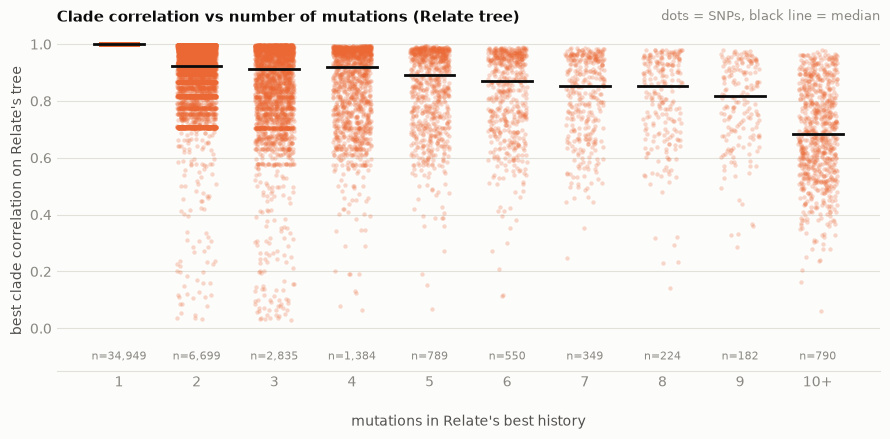

In [12]:

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
RELATE_C = "#eb6834"

max_shown = 10                                             # 10 or more mutations share one column
m = df.relate_mutations.clip(upper=max_shown)
cc = df.relate_best_clade_corr
counts = sorted(m.unique())
tick_labels = [f"{k}+" if k == max_shown else str(k) for k in counts]

fig, ax = plt.subplots(figsize=(9, 4.5))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# every SNP as a dot, spread sideways a little so overlapping dots stay visible
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.25, 0.25, len(m))
ax.scatter(m + jitter, cc, s=10, color=RELATE_C, alpha=0.25, linewidth=0, zorder=2)

# the median for each number of mutations, plus how many SNPs it is based on
for k in counts:
    vals = cc[m == k]
    ax.plot([k - 0.32, k + 0.32], [vals.median()] * 2, color=INK, linewidth=2, zorder=3)
    ax.text(k, -0.08, f"n={len(vals):,}", ha="center", va="top", fontsize=8, color=MUTED)

ax.set_xticks(counts, tick_labels)
ax.set_xlabel("mutations in Relate's best history", color=INK_2, labelpad=18)
ax.set_ylabel("best clade correlation on Relate's tree", color=INK_2)
ax.set_ylim(-0.15, 1.05)
ax.set_title("Clade correlation vs number of mutations (Relate tree)",
             loc="left", fontsize=11, fontweight="bold", color=INK)
ax.text(1.0, 1.02, "dots = SNPs, black line = median", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9, color=MUTED)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
fig.tight_layout()
plt.show()

In [13]:

# ---------------------------------------------------------------
# 4. by ALT count bin
# ---------------------------------------------------------------
by_freq = df.groupby("ALT_count_bin").agg(
    ALT_count_range=("ALT_count", lambda x: f"{x.min()}-{x.max()}"),
    SNPs=("position", "size"),
    pct_relate_1_mutation=("relate_mutations", lambda x: 100 * (x == 1).mean()),
    mean_relate_mutations=("relate_mutations", "mean"),
    median_dlog_best=("dlog_best", "median"),
    median_dlog_marginal=("dlog_marginal", "median"),
    median_relate_best_share=("relate_best_share", "median"),
    median_relate_best_clade_corr=("relate_best_clade_corr", "median"),
    pct_relate_time_inside=("relate_time_inside", lambda x: 100 * x.mean()),
)
print("\nby ALT count bin:")
print(by_freq.round(2).to_string())



by ALT count bin:
              ALT_count_range   SNPs  pct_relate_1_mutation  mean_relate_mutations  median_dlog_best  median_dlog_marginal  median_relate_best_share  median_relate_best_clade_corr  pct_relate_time_inside
ALT_count_bin                                                                                                                                                                                              
0                        1-40  35481                  83.49                   1.27             -0.86                 -0.86                       1.0                           1.00                   47.64
1                       41-80   2030                  49.26                   2.69             -8.59                 -8.54                       1.0                           0.99                   50.89
2                      81-120   1351                  44.49                   2.95            -10.47                -10.45                       1.0                 

# PLOTS

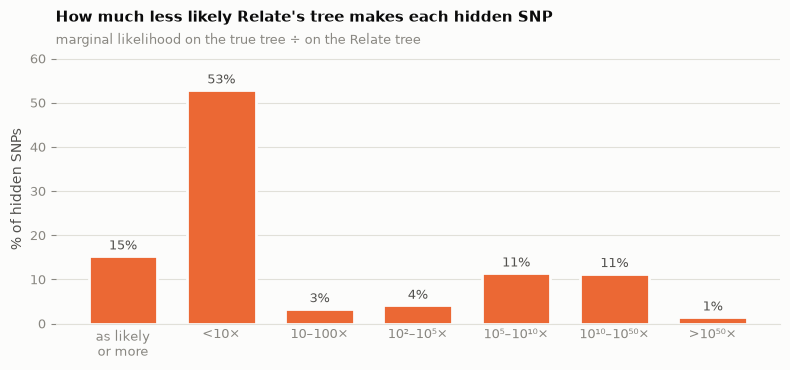

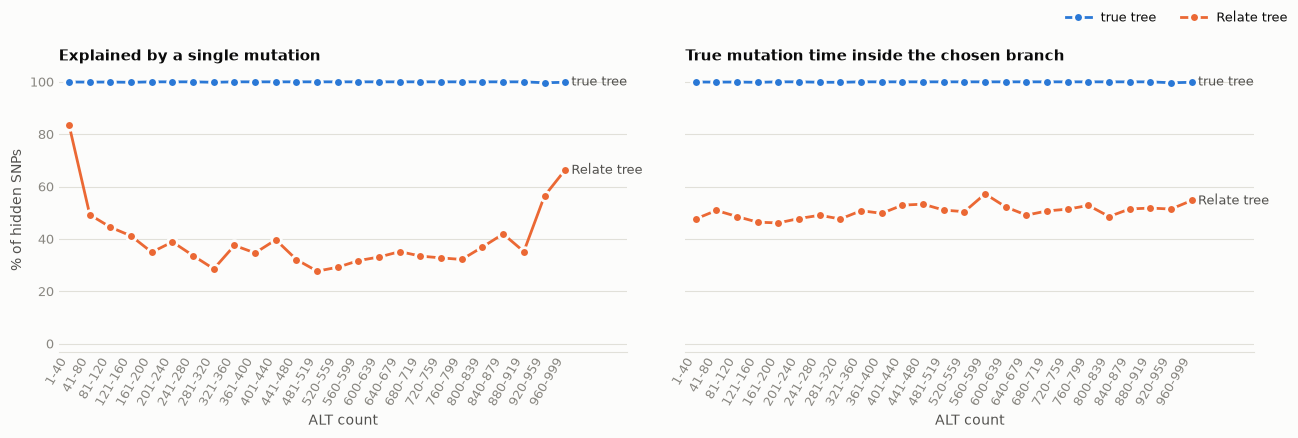

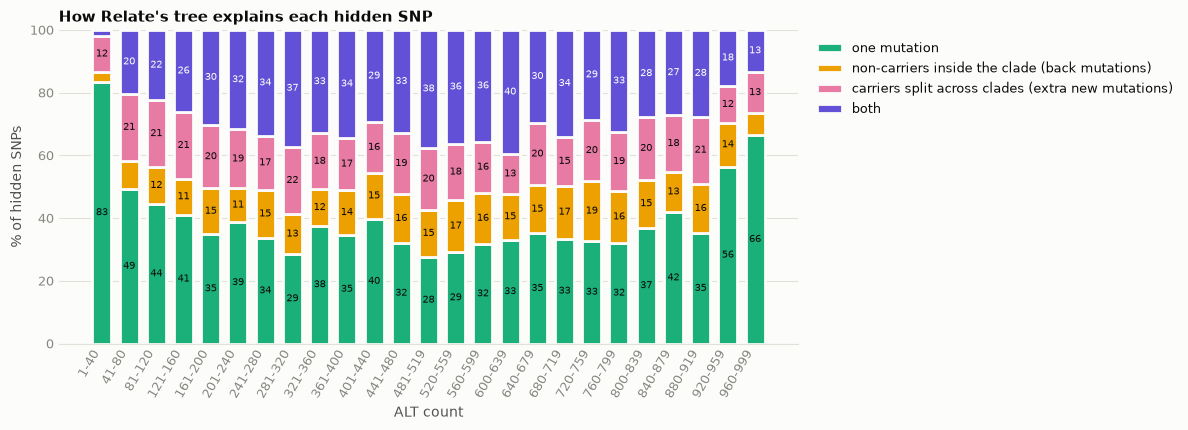

In [14]:
# colours: same palette as plot_tree.py; blue = true tree, orange = Relate
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
TRUE_C, RELATE_C = "#2a78d6", "#eb6834"
OUTCOME_C = ["#1baf7a", "#eda100", "#e87ba4", "#6250d6"]          # aqua, yellow, magenta, violet (blue/orange already mean true/Relate)
OUTCOME_TEXT = [INK, INK, INK, SURFACE]                             # label ink that reads on each fill

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 9,
})

# ALT count bins: use the bins already in results_df, labelled by the ALT counts actually in each
present = sorted(df.ALT_count_bin.dropna().unique())
ranges = df.groupby("ALT_count_bin").ALT_count.agg(["min", "max"])
bin_labels = [f"{ranges.loc[b, 'min']}-{ranges.loc[b, 'max']}" for b in present]
x = np.arange(len(present))

# ---------------------------------------------------------------
# 1. how much less likely does Relate make each hidden SNP?
# ---------------------------------------------------------------
orders = -df.dlog_marginal / np.log(10)           # orders of magnitude less likely than on the true tree
gap_bins = [-np.inf, 0, 1, 2, 5, 10, 50, np.inf]
gap_labels = ["as likely\nor more", "<10×", "10–100×", "10²–10⁵×", "10⁵–10¹⁰×", "10¹⁰–10⁵⁰×", ">10⁵⁰×"]
counts = pd.cut(orders, bins=gap_bins, labels=gap_labels).value_counts().reindex(gap_labels)
pct = 100 * counts / len(df)

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(gap_labels, pct, color=RELATE_C, width=0.7, edgecolor=SURFACE, linewidth=2)
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, p + 0.8, f"{p:.0f}%", ha="center", va="bottom",
            fontsize=9, color=INK_2)
ax.set_ylabel("% of hidden SNPs")
ax.set_title("How much less likely Relate's tree makes each hidden SNP", pad=24)
ax.text(0, 1.03, "marginal likelihood on the true tree ÷ on the Relate tree",
        transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
ax.set_ylim(0, pct.max() * 1.15)
ax.tick_params(axis="x", length=0)
fig.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 2. by ALT count bin: true tree vs Relate, two measures
# ---------------------------------------------------------------
g = df.groupby("ALT_count_bin")
panels = [
    ("Explained by a single mutation", lambda d, n: 100 * (d[f"{n}_mutations"] == 1).mean()),
    ("True mutation time inside the chosen branch", lambda d, n: 100 * d[f"{n}_time_inside"].mean()),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (title, stat) in zip(axes, panels):
    for name, colour, label in (("std", TRUE_C, "true tree"), ("relate", RELATE_C, "Relate tree")):
        y = [stat(g.get_group(b), name) for b in present]
        ax.plot(x, y, color=colour, linewidth=2, marker="o", markersize=7,
                markeredgecolor=SURFACE, markeredgewidth=2, label=label)
        ax.text(x[-1] + 0.3, y[-1], label, color=INK_2, fontsize=9, va="center")   # direct label
    ax.set_xticks(x, bin_labels, rotation=60, ha="right")
    ax.set_xlim(-0.5, len(present) - 0.5 + 2.5)
    ax.set_ylim(-3, 105)
    ax.set_xlabel("ALT count")
    ax.set_title(title)
    ax.tick_params(length=0)
axes[0].set_ylabel("% of hidden SNPs")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# ---------------------------------------------------------------
# 3. how Relate explains the hidden SNPs, by ALT count bin
# ---------------------------------------------------------------
kind = np.select(
    [df.relate_mutations == 1,
     (df.relate_new_mutations == 1) & (df.relate_back_mutations > 0),
     (df.relate_new_mutations > 1) & (df.relate_back_mutations == 0)],
    ["one mutation", "non-carriers inside the clade (back mutations)",
     "carriers split across clades (extra new mutations)"],
    default="both")
order = ["one mutation", "non-carriers inside the clade (back mutations)",
         "carriers split across clades (extra new mutations)", "both"]
share = (pd.crosstab(df.ALT_count_bin, kind, normalize="index") * 100).reindex(index=present, columns=order).fillna(0)

fig, ax = plt.subplots(figsize=(12, 4.4))
bottom = np.zeros(len(present))
for col, colour, ink in zip(order, OUTCOME_C, OUTCOME_TEXT):
    ax.bar(x, share[col], bottom=bottom, color=colour, width=0.7,
           edgecolor=SURFACE, linewidth=2, label=col)
    for xi, (b, h) in enumerate(zip(bottom, share[col])):
        if h >= 10:                                             # label segments big enough to read
            ax.text(xi, b + h / 2, f"{h:.0f}", ha="center", va="center", fontsize=7, color=ink)
    bottom += share[col].to_numpy()
ax.set_xticks(x, bin_labels, rotation=60, ha="right")
ax.set_xlabel("ALT count")
ax.set_ylabel("% of hidden SNPs")
ax.set_ylim(0, 100)
ax.set_title("How Relate's tree explains each hidden SNP")
ax.tick_params(length=0)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

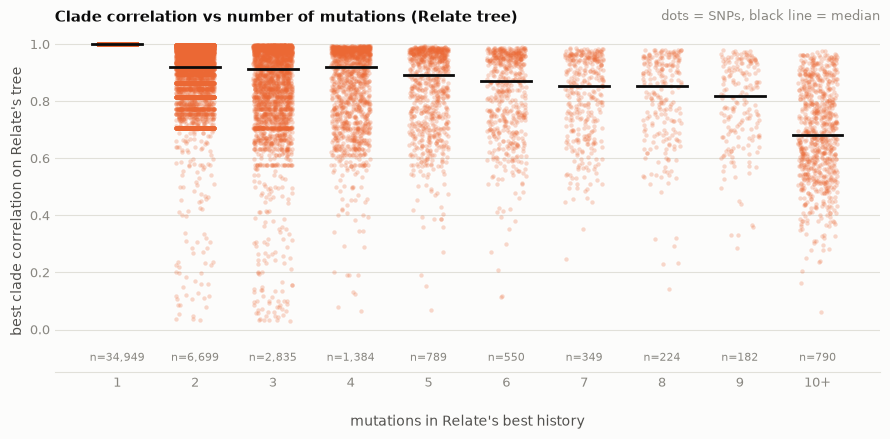

In [15]:

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
RELATE_C = "#eb6834"

max_shown = 10                                             # 10 or more mutations share one column
m = df.relate_mutations.clip(upper=max_shown)
cc = df.relate_best_clade_corr
counts = sorted(m.unique())
tick_labels = [f"{k}+" if k == max_shown else str(k) for k in counts]

fig, ax = plt.subplots(figsize=(9, 4.5))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# every SNP as a dot, spread sideways a little so overlapping dots stay visible
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.25, 0.25, len(m))
ax.scatter(m + jitter, cc, s=10, color=RELATE_C, alpha=0.25, linewidth=0, zorder=2)

# the median for each number of mutations, plus how many SNPs it is based on
for k in counts:
    vals = cc[m == k]
    ax.plot([k - 0.32, k + 0.32], [vals.median()] * 2, color=INK, linewidth=2, zorder=3)
    ax.text(k, -0.08, f"n={len(vals):,}", ha="center", va="top", fontsize=8, color=MUTED)

ax.set_xticks(counts, tick_labels)
ax.set_xlabel("mutations in Relate's best history", color=INK_2, labelpad=18)
ax.set_ylabel("best clade correlation on Relate's tree", color=INK_2)
ax.set_ylim(-0.15, 1.05)
ax.set_title("Clade correlation vs number of mutations (Relate tree)",
             loc="left", fontsize=11, fontweight="bold", color=INK)
ax.text(1.0, 1.02, "dots = SNPs, black line = median", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9, color=MUTED)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
fig.tight_layout()
plt.show()

# LD Score

In [50]:
# load results filename previously calculated
results_filename = "chr12_HapMapII_GRCh37_CEU500_seed1_10.00percent500000bp_25bins_seed42"

results = pd.read_csv(f"../../masked_recovery_comp/{results_filename}_results.csv")
results

,SNP position,max_corr,ALT_count,ALT_bin_num,n_retained_snps,max_r2,ld_score,optimized_n_retained_snps,optimized_max_r2,optimized_ld_score,optimized_top10_r2_sum,not_close
0,130919180,1.000000,1,0,3330,0.199199,1.594167,3330,0.199199,1.594167,0.956923,False
1,91013145,1.000000,1,0,3354,0.332666,1.835594,3354,0.332666,1.835594,0.866618,False
2,24190668,1.000000,2,0,3101,1.000000,7.777653,3101,1.000000,7.777653,4.677400,False
3,100836424,1.000000,1,0,3406,1.000000,3.221328,3406,1.000000,3.221328,2.171134,False
4,27350327,1.000000,10,0,3569,1.000000,103.055641,3569,1.000000,103.055641,10.000000,False
...,...,...,...,...,...,...,...,...,...,...,...,...
48746,933195,0.995869,411,10,3197,1.000000,154.325635,3197,1.000000,154.325635,10.000000,True
48747,86308660,1.000000,1,0,3127,1.000000,3.808461,3127,1.000000,3.808461,3.147621,False
48748,125020534,0.977248,605,15,3475,0.991648,48.501984,3475,0.991648,48.501984,9.056202,True
48749,81993680,1.000000,1,0,3487,0.249249,1.441472,3487,0.249249,1.441472,0.584952,False


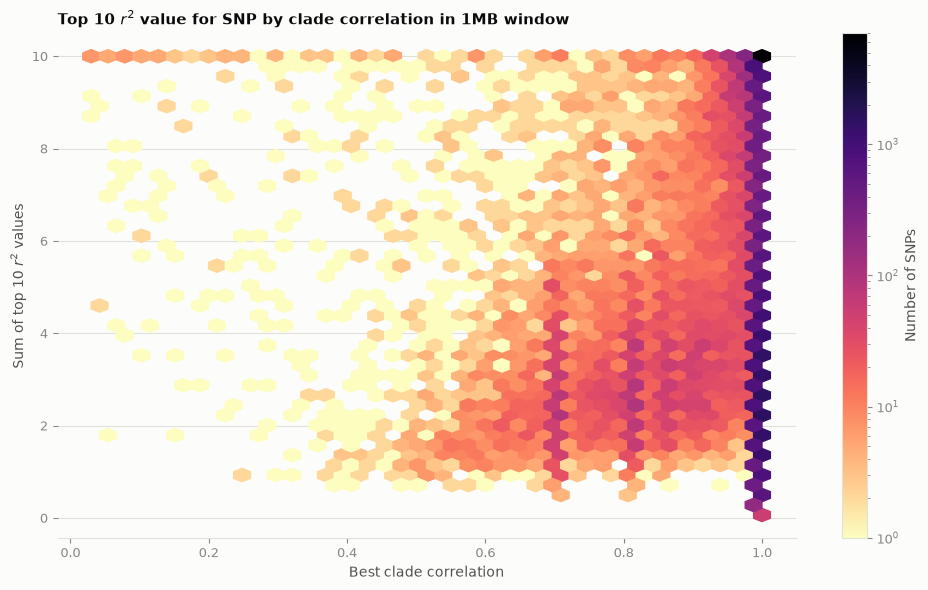

In [51]:
fig, ax = plt.subplots(figsize=(10, 6))

heatmap = ax.hexbin(
    results["max_corr"],
    results["optimized_top10_r2_sum"],
    gridsize=40,
    bins="log",
    mincnt=1,
    cmap="magma_r"
)
n = 100   # number of haplotypes in this analysis
# for phi, label in [(np.sqrt((n - 2) / (2 * (n - 1))), "1 of 2"),
#                    (np.sqrt(2 * (n - 3) / (3 * (n - 2))), "2 of 3"),
#                    (np.sqrt((n - 3) / (3 * (n - 1))), "1 of 3")]:
#     ax.axvline(phi, color="black", linewidth=0.8, linestyle="--")
#     ax.text(phi, ax.get_ylim()[1], label, ha="center", va="bottom", fontsize=8)

fig.colorbar(heatmap, ax=ax, label="Number of SNPs")

ax.set_xlabel("Best clade correlation")
ax.set_ylabel(r"Sum of top 10 $r^2$ values")
ax.set_title(r"Top 10 $r^2$ value for SNP by clade correlation in 1MB window")

fig.tight_layout()
fig.savefig("top10_r2_clade_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

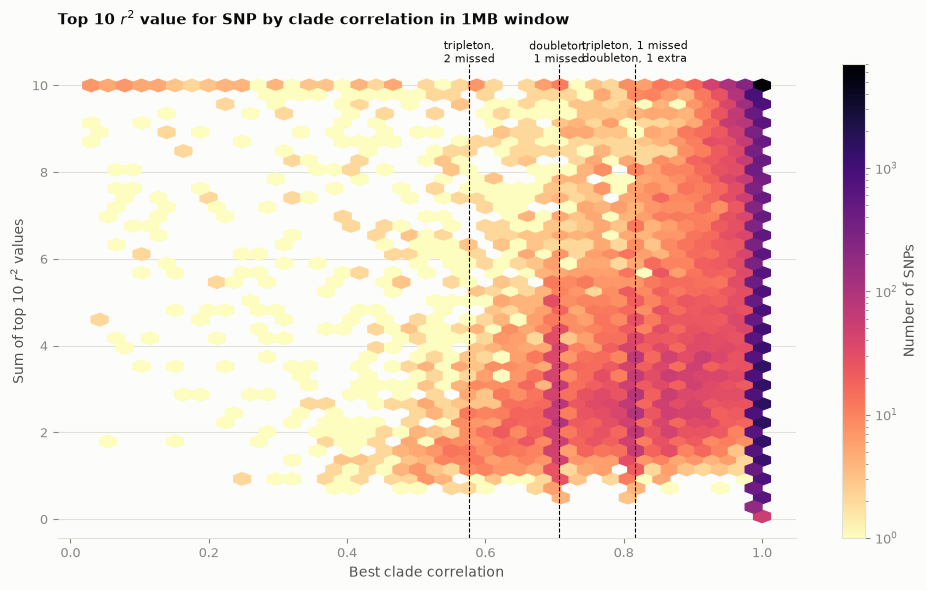

In [52]:
fig, ax = plt.subplots(figsize=(10, 6))

heatmap = ax.hexbin(
    results["max_corr"],
    results["optimized_top10_r2_sum"],
    gridsize=40,
    bins="log",
    mincnt=1,
    cmap="magma_r"
)

n = 1000   # number of haplotypes in this analysis


def phi_nested(small, big, n):
    """Clade correlation when one set sits inside the other (sizes small <= big)."""
    return np.sqrt(small * (n - big) / (big * (n - small)))


stripes = [
    (phi_nested(1, 3, n), "tripleton,\n2 missed"),
    (phi_nested(1, 2, n), "doubleton,\n1 missed"),
    (phi_nested(2, 3, n), "tripleton, 1 missed\ndoubleton, 1 extra"),
]

for phi, label in stripes:
    ax.axvline(phi, color="black", linewidth=0.8, linestyle="--")
    ax.text(phi, ax.get_ylim()[1], label, ha="center", va="bottom",
            fontsize=8, linespacing=1.1)

fig.colorbar(heatmap, ax=ax, label="Number of SNPs")

ax.set_xlabel("Best clade correlation")
ax.set_ylabel(r"Sum of top 10 $r^2$ values")
ax.set_title(r"Top 10 $r^2$ value for SNP by clade correlation in 1MB window", pad=28)

fig.tight_layout()
fig.savefig("top10_r2_clade_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

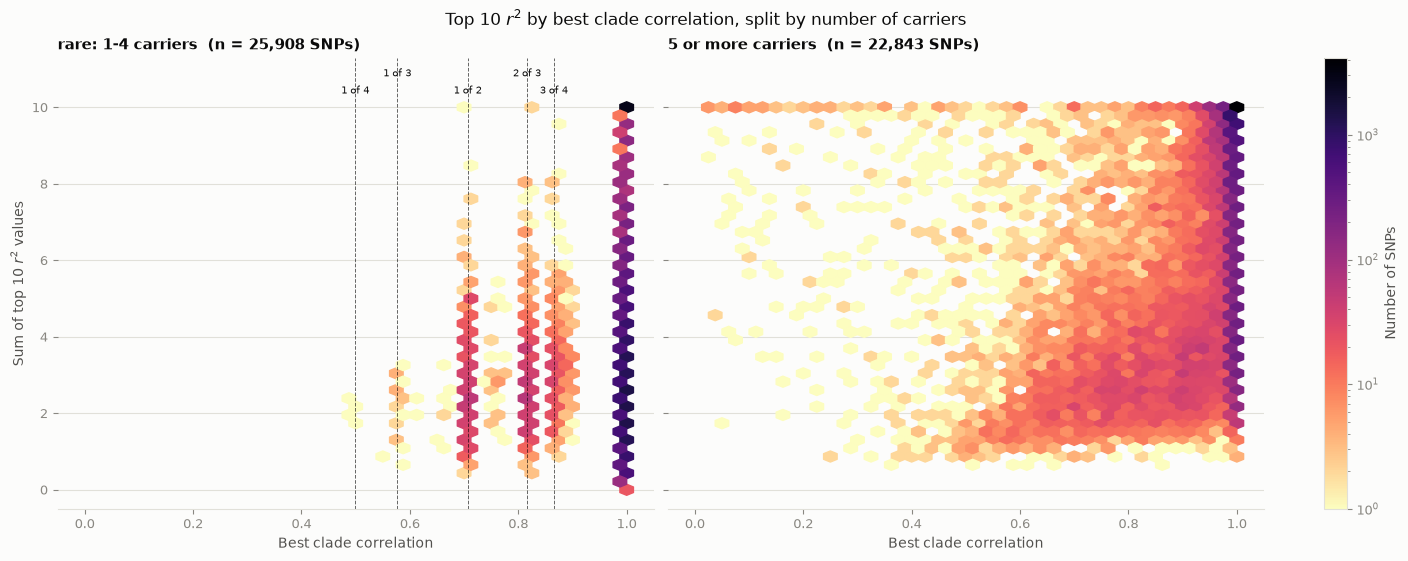

In [53]:
data = results                      # one row per masked SNP
x_col = "max_corr"          # best clade correlation
y_col = "optimized_top10_r2_sum"             # sum of the top 10 r^2 values
count_col = "ALT_count"            # number of carriers
n = 1000                            # number of haplotypes

groups = [
    ("rare: 1-4 carriers", data[data[count_col] <= 4]),
    ("5 or more carriers", data[data[count_col] >= 5]),
]

# predicted stripe positions for rare variants (best clade = some of the carriers, or 1 carrier + 1 non-carrier)
predicted = {
    "1 of 2": np.sqrt((n - 2) / (2 * (n - 1))),
    "2 of 3": np.sqrt(2 * (n - 3) / (3 * (n - 2))),
    "1 of 3": np.sqrt((n - 3) / (3 * (n - 1))),
    "3 of 4": np.sqrt(3 * (n - 4) / (4 * (n - 3))),
    "1 of 4": np.sqrt((n - 4) / (4 * (n - 1))),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True, layout="constrained")
norm = LogNorm(vmin=1, vmax=None)                  # same colour scale on both panels
hbs = []
for ax, (title, d) in zip(axes, groups):
    hb = ax.hexbin(d[x_col], d[y_col], gridsize=40, extent=(0, 1, 0, 10),
                   cmap="magma_r", norm=norm, mincnt=1)
    hbs.append(hb)
    if ax is axes[0]:                              # predicted lines on the rare panel only
        for i, (label, phi) in enumerate(sorted(predicted.items(), key=lambda kv: kv[1])):
            ax.axvline(phi, color="black", linewidth=0.7, linestyle="--", alpha=0.6)
            ax.text(phi, 10.3 + 0.45 * (i % 2), label, ha="center", va="bottom", fontsize=7)   # staggered so close labels don't overlap
    ax.set_title(f"{title}  (n = {len(d):,} SNPs)")
    ax.set_ylim(-0.5, 11.3)
    ax.set_xlabel("Best clade correlation")
axes[0].set_ylabel("Sum of top 10 $r^2$ values")

# one colour bar, scaled to the busier panel
vmax = max(h.get_array().max() for h in hbs)
for h in hbs:
    h.set_norm(LogNorm(vmin=1, vmax=vmax))
fig.colorbar(hbs[0], ax=axes, label="Number of SNPs")
fig.suptitle("Top 10 $r^2$ by best clade correlation, split by number of carriers")
plt.show()

# Off by 1 stuff

In [54]:
results[["missed", "extra"]] = results.apply(
    lambda r: pd.Series(infer_errors(r["max_corr"], int(r["ALT_count"]), n)), axis=1)
results["off_by"] = results["missed"] + results["extra"]   # NaN = more than 3 off

In [55]:
off = results["off_by"].fillna(4).clip(upper=4)
counts = off.value_counts().sort_index()
off_by_summary = pd.DataFrame({
    "SNPs": counts,
    "percent": (100 * counts / counts.sum()).round(1),
}).rename(index={0: "0", 1: "1", 2: "2", 3: "3", 4: "4+"})
off_by_summary.index.name = "off_by"
print(off_by_summary)


         SNPs  percent
off_by                
0       34949     71.7
1        3624      7.4
2        1773      3.6
3        1044      2.1
4+       7361     15.1


In [56]:
# split into missed vs extra
pd.crosstab(results["missed"], results["extra"], margins=True)

extra,0.0,1.0,2.0,3.0,All
missed,,,,,
0.0,34949,1285,441,256,36931
1.0,2339,227,86,0,2652
2.0,1105,116,0,0,1221
3.0,586,0,0,0,586
All,38979,1628,527,256,41390


In [57]:
# off-by counts for each allele count (5+ grouped together)
carriers = results["ALT_count"].clip(upper=5).replace(5, "5+")
pd.crosstab(carriers, results["off_by"].fillna(4).replace(4, "4+"), margins=True)

off_by,0.0,1.0,2.0,3.0,4+,All
ALT_count,,,,,,
1,14790,0,0,0,0,14790
2,5164,634,0,0,0,5798
3,2635,539,37,2,4,3217
4,1571,319,191,21,1,2103
5+,10789,2132,1545,1021,7356,22843
All,34949,3624,1773,1044,7361,48751


# Whats with the hight r^2 low clade corr ?

In [65]:
odd = results[(results["optimized_top10_r2_sum"] > 9.99) & (results["max_corr"] < 0.9)]
print(len(odd), "SNPs with 10 perfect LD partners but clade correlation < 0.9")

print("ALT_count distribution")
print(odd["ALT_count"].describe())

123 SNPs with 10 perfect LD partners but clade correlation < 0.9
ALT_count distribution
count    123.000000
mean     738.455285
std      364.760471
min        2.000000
25%      651.000000
50%      953.000000
75%      997.500000
max      999.000000
Name: ALT_count, dtype: float64


In [32]:
odd[["SNP position", "ALT_count", "max_corr"]].sort_values("max_corr").head(20)

,SNP position,ALT_count,max_corr
45358,46045611,999,0.030034
8264,17021997,999,0.032997
5731,97164840,999,0.033463
44816,70341839,999,0.035191
36644,125837348,999,0.036353
7167,125818888,999,0.036501
15249,83307140,999,0.042093
35368,29120330,999,0.047313
25522,31048507,999,0.055242
37531,132903292,999,0.058218


In [41]:
def best_clade_corr(tree, carriers):
    """Best phi over all branches. carriers: boolean array in ts.samples() order."""
    samples = tree.tree_sequence.samples()
    is_carrier = dict(zip(samples, carriers.astype(int)))
    n, c = len(samples), int(carriers.sum())
    below, best, best_node = {}, -np.inf, None
    for u in tree.nodes(order="postorder"):
        below[u] = is_carrier.get(u, 0) + sum(below[ch] for ch in tree.children(u))
        b = tree.num_samples(u)
        if u == tree.root or not 0 < b < n:
            continue
        p = clade_phi(below[u], b, c, n)
        if p > best:
            best, best_node = p, u
    return best, best_node


def genotypes_at(ts, pos):
    var = next(ts.variants(left=pos, right=pos + 1))
    return var.genotypes == 1


rows = []
for pos in odd["SNP position"]:
    x = genotypes_at(ts_std, pos)
    tree = ts_masked.at(pos)
    rows.append(dict(
        position=pos,
        ALT_count=int(x.sum()),
        phi_carriers=best_clade_corr(tree, x)[0],
        phi_noncarriers=best_clade_corr(tree, ~x)[0],
    ))
check = pd.DataFrame(rows)
check["split_right_root_wrong"] = check["phi_noncarriers"] > 1 - 1e-9
print(check["split_right_root_wrong"].value_counts())
print(check.sort_values("phi_carriers").head(20))

split_right_root_wrong
True     73
False    50
Name: count, dtype: int64
      position  ALT_count  phi_carriers  phi_noncarriers  \
114   46045611        999      0.030034          1.00000   
19    17021997        999      0.032997          1.00000   
12    97164840        999      0.033463          1.00000   
112   70341839        999      0.035191          1.00000   
91   125837348        999      0.036353          1.00000   
15   125818888        999      0.036501          1.00000   
41    83307140        999      0.042093          1.00000   
89    29120330        999      0.047313          1.00000   
65    31048507        999      0.055242          1.00000   
94   132903292        999      0.058218          1.00000   
25    64949956        997      0.062771          1.00000   
113  123976195        998      0.063072          1.00000   
1    131707337        999      0.070916          1.00000   
73    64314279        993      0.071301          0.75479   
10    26760247        999  

In [43]:
relate_positions = set(np.round(ts_masked.tables.sites.position).astype(int))
relate_breaks = ts_masked.breakpoints(as_array=True)


def perfect_ld_partners(pos, window=500_000, r2_min=0.999):
    x = genotypes_at(ts_std, pos)
    left, right = max(0, pos - window), min(ts_std.sequence_length, pos + window)
    rows = []
    for v in ts_std.variants(left=left, right=right):
        p2 = v.site.position
        if p2 == pos:
            continue
        y = v.genotypes == 1
        if y.all() or not y.any():
            continue
        r = np.corrcoef(x, y)[0, 1]
        if r ** 2 < r2_min:
            continue
        rows.append(dict(
            partner=int(p2),
            distance_kb=round((p2 - pos) / 1000, 1),
            r=round(r, 3),                                   # -1 = mirror image
            in_relate_input=int(round(p2)) in relate_positions,
            relate_trees_between=abs(int(np.searchsorted(relate_breaks, p2))
                                     - int(np.searchsorted(relate_breaks, pos))),
            phi_at_partner_pos=round(best_clade_corr(ts_masked.at(p2), y)[0], 3),
            phi_at_snp_pos=round(best_clade_corr(ts_masked.at(pos), y)[0], 3),
        ))
    return pd.DataFrame(rows)


worst = odd.sort_values("max_corr")["SNP position"].head(3)
for pos in worst:
    print(f"\nmasked SNP at {pos:,}")
    print(perfect_ld_partners(pos).to_string(index=False))


masked SNP at 46,045,611
 partner  distance_kb    r  in_relate_input  relate_trees_between  phi_at_partner_pos  phi_at_snp_pos
45602616       -443.0 -1.0             True                    39                 1.0             1.0
45746031       -299.6 -1.0             True                    29                 1.0             1.0
46044204         -1.4 -1.0             True                     0                 1.0             1.0
46054858          9.2 -1.0             True                     0                 1.0             1.0
46056909         11.3 -1.0             True                     0                 1.0             1.0
46061798         16.2 -1.0             True                     0                 1.0             1.0
46066573         21.0 -1.0             True                     0                 1.0             1.0
46070025         24.4 -1.0             True                     0                 1.0             1.0
46075056         29.4 -1.0             True             

In [44]:
results["phi_unrooted"] = results["max_corr"]
not_perfect = results["max_corr"] < 1 - 1e-9

for i, pos in results.loc[not_perfect, "SNP position"].items():
    x = genotypes_at(ts_std, pos)
    tree = ts_masked.at(pos)
    results.at[i, "phi_unrooted"] = max(best_clade_corr(tree, x)[0],
                                        best_clade_corr(tree, ~x)[0])

results["root_only_error"] = not_perfect & (results["phi_unrooted"] > 1 - 1e-9)
print(f"SNPs fixed by ignoring the root: {results['root_only_error'].sum():,} "
      f"({100 * results['root_only_error'].mean():.1f}% of all SNPs)")
print(results.loc[results["root_only_error"], "ALT_count"].describe())

SNPs fixed by ignoring the root: 281 (0.6% of all SNPs)
count    281.000000
mean     710.857651
std      342.418751
min        2.000000
25%      487.000000
50%      895.000000
75%      991.000000
max      999.000000
Name: ALT_count, dtype: float64


In [68]:
check["group"] = pd.cut(check["ALT_count"], [0, 10, 500, 992, 1000],
                        labels=["rare (≤10)", "11–500", "501–992", "near-fixed (993+)"])
print(pd.crosstab(check["group"], check["split_right_root_wrong"], margins=True))

# the rare ones, which shouldn't happen with 10 perfect partners
print(check[check["ALT_count"] <= 10])

split_right_root_wrong  False  True  All
group                                   
rare (≤10)                 11     0   11
11–500                     15     3   18
501–992                    22    28   50
near-fixed (993+)           2    42   44
All                        50    73  123
      position  ALT_count  phi_carriers  phi_noncarriers  \
26    84101744          7      0.844304         0.122392   
45    84101501          7      0.844304         0.122392   
49    83901203          2      0.706753         0.059559   
51    41891003          3      0.816087         0.062010   
67   121078580          9      0.881029         0.067943   
78    83033358          3      0.816087         0.158756   
80    53410652          6      0.815676         0.770041   
95    84076971          7      0.844304         0.934943   
98   116649907          5      0.773819         0.631504   
105   53427624          6      0.815676         0.770041   
121   41255595          7      0.844304         0.086

999 carriers, non-carriers: [np.int32(343)]


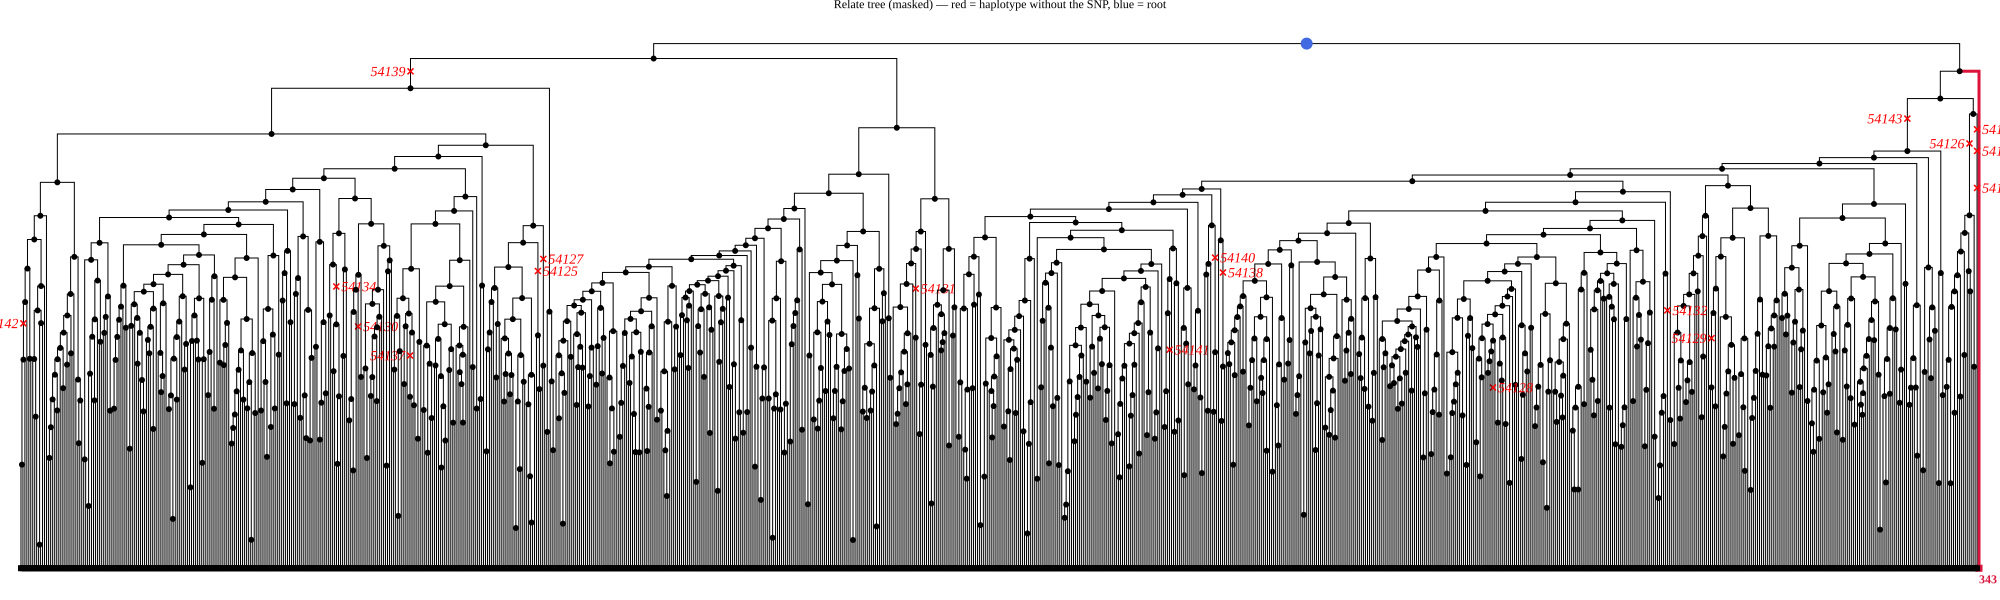

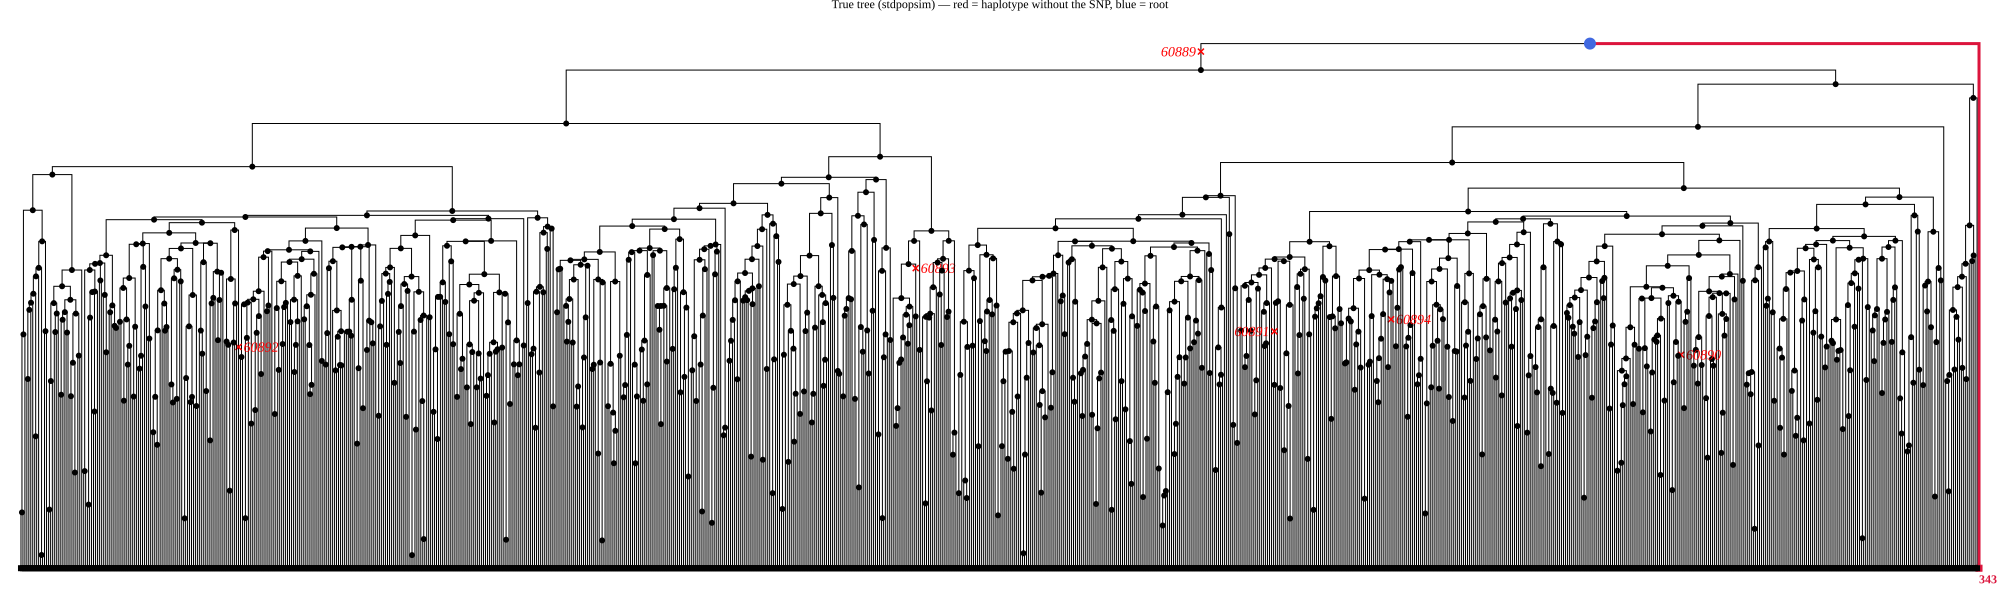

In [63]:
pos = 17021997
tree_std = ts_std.at(pos)
tree_masked = ts_masked.at(pos)

sample_ids = ts_std.samples()
carrier = genotypes_at(ts_std, pos)              # True = carries the SNP
noncarrier_nodes = sample_ids[~carrier]
print(f"{carrier.sum()} carriers, non-carriers: {list(noncarrier_nodes)}")

wide_fmt = (2000, 600)
node_label_style = (
    ".node > .lab {font-size: 80%}"
    ".leaf > .lab {text-anchor: start; transform: rotate(90deg) translate(6px)}"
)

# label only the non-carrier(s)
node_labels = {int(u): str(u) for u in noncarrier_nodes}


def highlight_style(tree):
    style = ".leaf > .lab {font-size: 12px;}"
    for node in noncarrier_nodes:
        style += f"""
        .node.n{int(node)} > .sym {{fill: crimson; stroke: crimson; r: 5px;}}
        .node.n{int(node)} > .lab {{fill: crimson; font-weight: bold;}}
        .node.n{int(node)} > .edge {{stroke: crimson; stroke-width: 3px;}}
        """
    style += f".node.n{tree.root} > .sym {{fill: royalblue; r: 6px;}}"   # root in blue
    return style


display(SVG(tree_masked.draw_svg(
    title="Relate tree (masked) — red = haplotype without the SNP, blue = root",
    size=wide_fmt,
    node_labels=node_labels,
    time_scale="log_time",
    style=node_label_style + highlight_style(tree_masked),
)))

display(SVG(tree_std.draw_svg(
    title="True tree (stdpopsim) — red = haplotype without the SNP, blue = root",
    size=wide_fmt,
    node_labels=node_labels,
    time_scale="log_time",
    style=node_label_style + highlight_style(tree_std),
)))